In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
# Generate Synthetic Dataset
def generate_dataset(num_samples, num_features, noise=0.1):
    #np.random.seed(42)  # For reproducibility
    X = np.random.randn(num_samples, num_features)  # Matrix of order num_samples x num_features
    true_weights = np.random.randn(num_features)   
    true_bias = np.random.randn()
    y = X @ true_weights + true_bias + noise * np.random.randn(num_samples)
    return X, y, true_weights, true_bias

In [3]:
# Matrix Inversion Solution
def matrix_inversion_solution(X, Y):
    X_matrix = np.hstack((np.ones((X.shape[0], 1)), X))
    Y_matrix = Y.reshape(-1, 1)
    
    # Use the normal equation: theta = (X^T X)^{-1} X^T Y
    X_transpose_X = np.dot(X_matrix.T, X_matrix)
    X_transpose_X_inv = np.linalg.inv(X_transpose_X)
    X_transpose_Y = np.dot(X_matrix.T, Y_matrix)
    
    w = np.dot(X_transpose_X_inv, X_transpose_Y)
    return w  # Return weight vector

In [4]:
# Gradient Descent Implementation
def gradient_descent(X, y, learning_rate, num_iterations):
    num_samples, num_features = X.shape
    # Initialize weight vector and bias
    weights = np.zeros(num_features)
    bias = 0.0
    
    # To store the loss at each iteration
    loss_history = []

    for i in range(num_iterations):
        # Compute predictions
        y_pred = X @ weights + bias

        
        # Compute loss (Mean Squared Error)
        loss = np.mean((y_pred - y) ** 2)
        loss_history.append(loss)
        
        
        # Compute gradients
        dw = (2 / num_samples) * (X.T @ (y_pred - y))
        db = (2 / num_samples) * np.sum(y_pred - y)
        
        # Update weights and bias
        weights = weights - learning_rate * dw
        bias = bias - learning_rate * db
        
        
        
    # Compute final loss (Mean Squared Error)
    y_pred = X @ weights + bias
    loss = np.mean((y_pred - y) ** 2)

    return weights, bias, loss, loss_history

In [5]:
# Generate data
# Example with one feature

num_samples = 10
num_features = 1
X, y, true_weights, true_bias = generate_dataset(num_samples, num_features)
#print("True Weights:", true_weights)
#print("True Bias:", true_bias)

# Generated data
print("X: ",X)
print("y: ",y)

X:  [[-0.27923894]
 [ 0.76364502]
 [-1.23004058]
 [-2.14210794]
 [-0.56116195]
 [ 0.61267935]
 [ 0.26747137]
 [ 1.30863667]
 [ 0.62255203]
 [ 0.82114899]]
y:  [-0.09949718  0.30575351 -0.27620965 -0.58192291 -0.05691678  0.07229052
 -0.13501235  0.42553713  0.02887547  0.30602397]


In [6]:
# Matrix Inversion Solution
start_time1 = time.time()
w_vector = matrix_inversion_solution(X, y)
matrix_inv_time = time.time() - start_time1
    
print("Time taken by matrix inversion solution: ",matrix_inv_time," seconds")
print("Matrix Inversion solution: ",w_vector)

# Here the first component of w_vector is the bias and the second component is the weight

print("\nBias computed by matrix inversion solution: ", w_vector[0])
print("Weight computed by matrix inversion solution: ", w_vector[1])

Time taken by matrix inversion solution:  0.0013649463653564453  seconds
Matrix Inversion solution:  [[-0.00594729]
 [ 0.26361038]]

Bias computed by matrix inversion solution:  [-0.00594729]
Weight computed by matrix inversion solution:  [0.26361038]


In [7]:
# Perform Gradient Descent
learning_rate = 0.1
num_iterations = 100

start_time2 = time.time()
learned_weights, learned_bias, loss, loss_history = gradient_descent(X, y, learning_rate, num_iterations)

gradient_descent_time = time.time() - start_time2
print("\nTime taken by gradient descent: ", gradient_descent_time," seconds")
    
print("\nLearned Weight:", learned_weights)
print("Learned Bias:", learned_bias)


# Compare true and learned weights and bias
#print("\nDifference between true and learned biases:", true_bias - learned_bias)          # This is a scalar
#print("\nDifference between true and learned weights:", true_weights - learned_weights)   # This is a vector


print("Loss (Mean squared error) with the learned weight and learned bias:", loss)


Time taken by gradient descent:  0.012297630310058594  seconds

Learned Weight: [0.26361038]
Learned Bias: -0.005947290818750276
Loss (Mean squared error) with the learned weight and learned bias: 0.010511370607644854


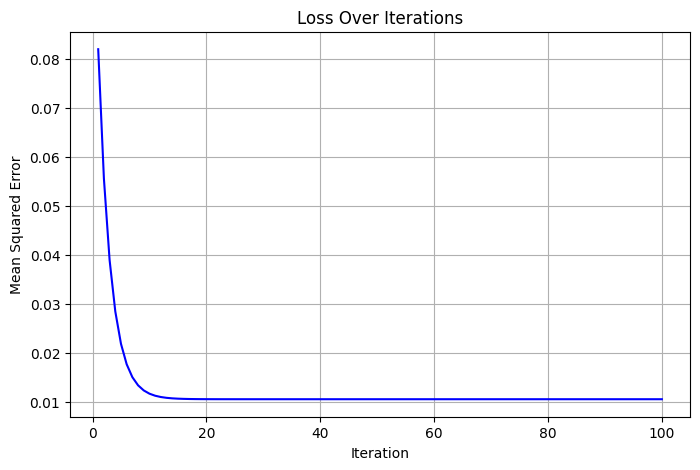

In [8]:
# Plot the loss over iterations
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_iterations + 1), loss_history, color='blue')
plt.title("Loss Over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()

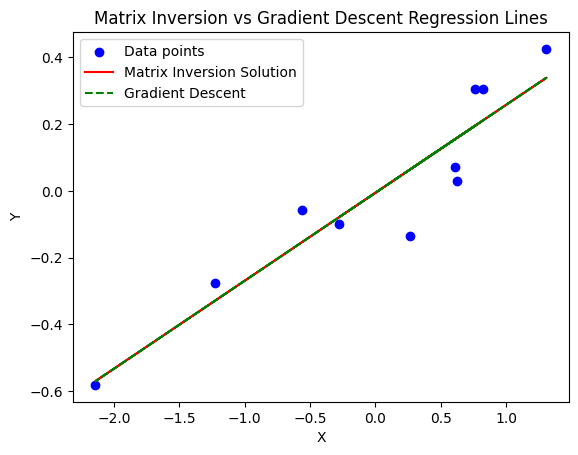

In [9]:
plt.scatter(X, y, color='blue', label='Data points')
plt.plot(X, X @ w_vector[1] + w_vector[0,0], color='red', label='Matrix Inversion Solution')  
plt.plot(X, X @ learned_weights + learned_bias, color='green', linestyle='--', label='Gradient Descent')
plt.title('Matrix Inversion vs Gradient Descent Regression Lines')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [10]:
# Suppose the learning rate is too high.


# Perform Gradient Descent
learning_rate = 2
num_iterations = 100

start_time2 = time.time()
learned_weights, learned_bias, loss, loss_history = gradient_descent(X, y, learning_rate, num_iterations)

gradient_descent_time = time.time() - start_time2
print("\nTime taken by gradient descent: ", gradient_descent_time," seconds")
    
print("\nLearned Weights:", learned_weights)
print("Learned Bias:", learned_bias)


# Compare true and learned weights and bias
#print("\nDifference between true and learned biases:", true_bias - learned_bias)          
#print("\nDifference between true and learned weights:", true_weights - learned_weights)   


print("Loss (Mean squared error) with the learned weights and learned bias:", loss)


Time taken by gradient descent:  0.009606361389160156  seconds

Learned Weights: [-1.66315338e+49]
Learned Bias: -7.884491494980018e+48
Loss (Mean squared error) with the learned weights and learned bias: 3.5185732761371036e+98


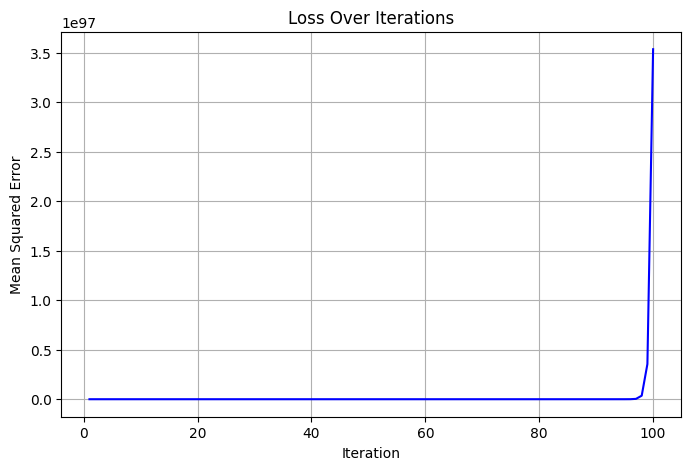

In [11]:
# Plot the loss over iterations
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_iterations + 1), loss_history, color='blue')
plt.title("Loss Over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()

In [12]:
# EXAMPLE WITH MORE FEATURES


# Generate data

num_samples = 1000000
num_features = 100
X, y, true_weights, true_bias = generate_dataset(num_samples, num_features)
#print("True Weights:", true_weights)
#print("True Bias:", true_bias)

# Generated data
#print("X: ",X)
#print("y: ",y)

In [14]:
# Matrix Inversion Solution
start_time1 = time.time()
w_vector = matrix_inversion_solution(X, y)
matrix_inv_time = time.time() - start_time1
    
print("Time taken by matrix inversion solution: ",matrix_inv_time," seconds")
#print("Matrix Inversion solution: ",w_vector)

# Here the first component of w_vector is the bias and the remaining components are the weights

print("\nBias computed by matrix inversion solution: ", w_vector[0])
print("Weights computed by matrix inversion solution: ", w_vector[1:len(w_vector)])

Time taken by matrix inversion solution:  2.3327207565307617  seconds

Bias computed by matrix inversion solution:  [-1.05884775]
Weights computed by matrix inversion solution:  [[ 0.38806557]
 [ 1.14434442]
 [-0.24645136]
 [ 0.96425699]
 [-0.21714827]
 [ 0.48878685]
 [ 1.64029848]
 [ 2.22912848]
 [-1.33086173]
 [ 1.02633496]
 [ 1.4647143 ]
 [-0.49822191]
 [ 0.93306575]
 [ 0.84602461]
 [-0.02855222]
 [-1.54125611]
 [ 0.44094435]
 [-1.04525372]
 [ 0.02926844]
 [-0.97593896]
 [ 0.73053573]
 [ 0.65338518]
 [-0.73097993]
 [-0.70658659]
 [ 0.53639497]
 [-0.35448985]
 [ 0.38435944]
 [ 0.29671616]
 [ 0.61384305]
 [ 1.9331136 ]
 [-0.6561137 ]
 [ 0.79159739]
 [ 0.73689983]
 [ 2.37267324]
 [ 0.74370378]
 [-0.01790103]
 [-0.42916229]
 [-0.11061869]
 [-0.23299126]
 [-0.34809431]
 [ 0.36983506]
 [-0.58318088]
 [-0.30957687]
 [-0.5159121 ]
 [ 0.57172196]
 [ 0.07680756]
 [-2.21510893]
 [ 0.44784371]
 [-0.72183089]
 [ 1.19013368]
 [ 0.4227861 ]
 [-0.14180726]
 [ 0.17235768]
 [ 0.75624768]
 [ 1.3720652

In [15]:
# Perform Gradient Descent
learning_rate = 0.1
num_iterations = 100

start_time2 = time.time()
learned_weights, learned_bias, loss, loss_history = gradient_descent(X, y, learning_rate, num_iterations)

gradient_descent_time = time.time() - start_time2
print("\nTime taken by gradient descent: ", gradient_descent_time," seconds")
    
print("\nLearned Weight:", learned_weights)
print("Learned Bias:", learned_bias)


# Compare true and learned weights and bias
#print("\nDifference between true and learned biases:", true_bias - learned_bias)          
#print("\nDifference between true and learned weights:", true_weights - learned_weights)   


print("Loss (Mean squared error) with the learned weight and learned bias:", loss)


Time taken by gradient descent:  22.00612449645996  seconds

Learned Weight: [ 0.38806557  1.14434442 -0.24645136  0.96425699 -0.21714827  0.48878685
  1.64029848  2.22912848 -1.33086173  1.02633496  1.4647143  -0.49822191
  0.93306575  0.84602461 -0.02855222 -1.54125611  0.44094435 -1.04525372
  0.02926844 -0.97593896  0.73053573  0.65338518 -0.73097993 -0.70658659
  0.53639497 -0.35448985  0.38435944  0.29671616  0.61384305  1.9331136
 -0.6561137   0.79159739  0.73689983  2.37267324  0.74370378 -0.01790103
 -0.42916229 -0.11061869 -0.23299126 -0.34809431  0.36983506 -0.58318088
 -0.30957687 -0.5159121   0.57172196  0.07680756 -2.21510893  0.44784371
 -0.72183089  1.19013368  0.4227861  -0.14180726  0.17235768  0.75624768
  1.37206529 -0.59703869 -1.07571224  0.40900692 -0.94106586  0.48391432
 -0.78017771  1.88080053  1.35975202 -0.44659153 -1.17637281 -1.8600602
  0.83406042 -0.61398762 -2.44363432  0.2306973   0.12139895 -1.1170572
  2.02435225  1.89575873 -0.72011794  0.36368684 

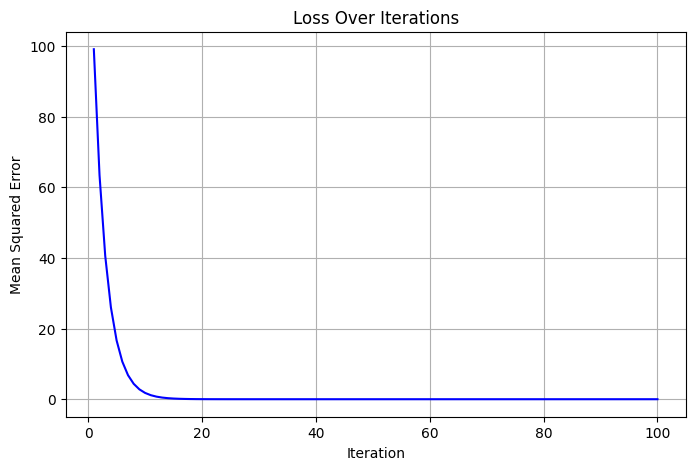

In [16]:
# Plot the loss over iterations
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_iterations + 1), loss_history, color='blue')
plt.title("Loss Over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()

EXERCISES:

1. Observe the effect of low learning rate on the convergence of gradient descent.
2. Observe the effect of high learning rate on the convergence of gradient descent.
3. Change the parameters to get an example where the matrix inversion solution is slower than gradient descent.